In [1]:
import numpy as np
import pandas as pd
print(pd.__version__)


2.3.3


In [2]:
df = pd.read_csv("11) Powerplant dataset.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT=> tempreture
# V => vaccum
# AP => pressure
# RH => humidity

# PE => produced energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
# Split out data
from sklearn.model_selection import train_test_split

X_train, X_test , y_train , y_test = train_test_split(
    X , y, test_size = 0.2, random_state=42
)

In [9]:
df.shape

(9568, 5)

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
type(X_train_scaled)

numpy.ndarray

In [12]:
type(y_train)
y_train.shape

(7654,)

In [13]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [14]:
# nn - neural network
print(type(X_train_scaled))
y_train_tensor

<class 'numpy.ndarray'>


tensor([[442.7500],
        [432.5200],
        [428.8000],
        ...,
        [464.2600],
        [440.4500],
        [484.4400]])

In [15]:
type(y_train)
y_train.shape

(7654,)

In [16]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


In [17]:
train_loader = DataLoader(train_dataset, batch_size= 32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size= 32)

### Deep Learning


In [18]:
# Build our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden
            nn.Linear(X_train.shape[1] , 6),
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
    
            #Output layer
            nn.Linear(6, 1),
        )

    def forward(self, X):
        return self.model(X)

    # backword prapogation function automaticaly apply
    # Autograd can automaticaly work

In [19]:
import torch.optim as optim
model = ANN()

#Loss, optimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [20]:
# Architecture are ready

In [22]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")
epochs = 100

for epoch in range(epochs):
    model.train()

    running_loss = 0.0 # totle training loss for 1 epoch
    
    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()

        outputs= model(xb) # forword prop .......   predicted outputs for this batch
        loss = crietrion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step()   # paras update

        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    #Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():  # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> training loss = {epoch_train_loss} & val loss = {epoch_val_loss} ")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") # .pt or .pth

epoch 1/100 ==> training loss = 205454.369140625 & val loss = 201684.890625 
epoch 2/100 ==> training loss = 189942.86139322916 & val loss = 172007.46875 
epoch 3/100 ==> training loss = 145547.4281575521 & val loss = 117031.015625 
epoch 4/100 ==> training loss = 93565.8635579427 & val loss = 73424.3984375 
epoch 5/100 ==> training loss = 59576.05335286458 & val loss = 45667.046875 
epoch 6/100 ==> training loss = 34096.96372477213 & val loss = 23008.751953125 
epoch 7/100 ==> training loss = 15883.034000651041 & val loss = 10154.2470703125 
epoch 8/100 ==> training loss = 8010.7554646809895 & val loss = 5978.16162109375 
epoch 9/100 ==> training loss = 5471.599495442709 & val loss = 4486.6337890625 
epoch 10/100 ==> training loss = 4255.927760314941 & val loss = 3585.31494140625 
epoch 11/100 ==> training loss = 3426.098622639974 & val loss = 2912.12109375 
epoch 12/100 ==> training loss = 2784.7408594767253 & val loss = 2376.11865234375 
epoch 13/100 ==> training loss = 2275.6135477

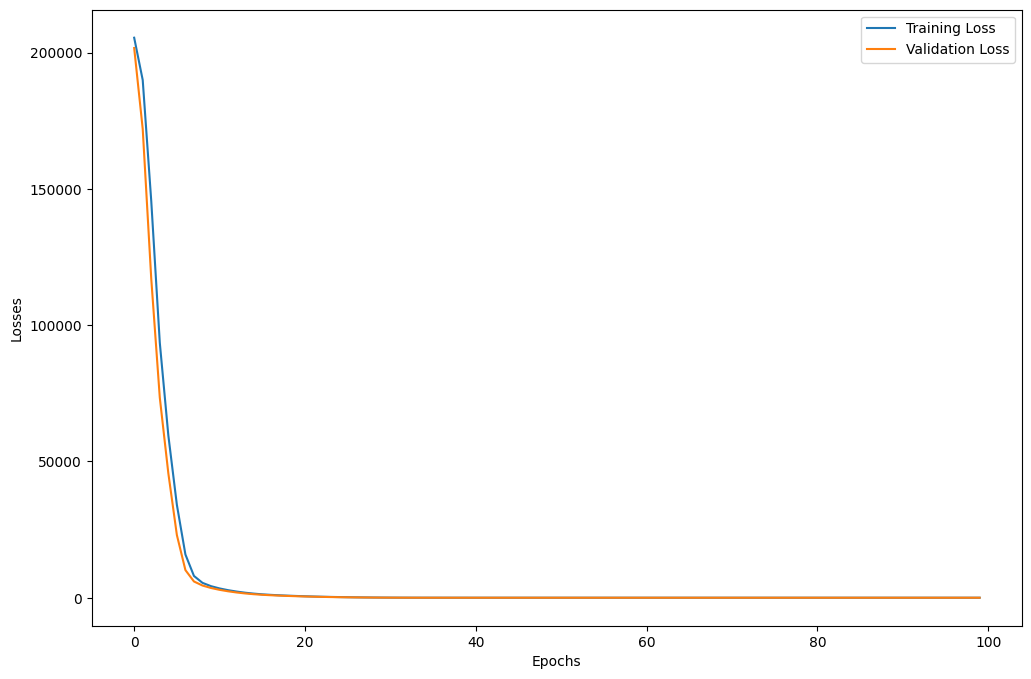

In [23]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss" : val_losses
})

plt.figure(figsize =(12,8))
plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [24]:
# Loading the best Model 
model.load_state_dict(torch.load("best_model.pt"))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22888\1949016369.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pt"))


<All keys matched successfully>

In [25]:
# Evaluate our model 

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds , y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE :", train_mse_loss)
print("Testing MSE :", test_mse_loss)


Training MSE : tensor(20.3695)
Testing MSE : tensor(18.6413)


In [26]:
from sklearn.metrics import r2_score

print("r^2 score = " , r2_score(y_test , test_preds))


r^2 score =  0.9348536336071762


In [29]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Value"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Value,Actual Values
0,435.169952,433.27
1,436.533783,438.16
2,461.210297,458.42
3,476.078491,480.82
4,435.164337,441.41
...,...,...
1909,451.147125,456.70
1910,431.375458,438.04
1911,467.528717,467.80
1912,430.751221,437.14
